# Análise Comparativa: Evolução Diferencial (DE) vs AG vs DETO vs DASE

Este notebook carrega os resultados gerados por `scripts/run_de_deto_dase.py` (`runs.csv`, `events.csv` e `curves.npz`) e gera:
1. **Tabelas comparativas** (Macro-F1, Acurácia, Kappa e Macro-F1 em janela);
2. **Visualizações comparativas** entre DE (S1–S6), AG (S1–S6), DETO, DASE, baselines e benchmarks;
3. **Testes estatísticos** (Friedman + Nemenyi com diagrama CD, Wilcoxon pareado com correção de Holm e tamanho de efeito $\hat{A}_{12}$);
4. **Curvas temporais** ao longo das streams com marcação dos drifts;
5. **Reação pós-drift, convergência e custo computacional** (avaliações e tempo de replay).

In [13]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.stats import a12, a12_label, cd_diagram, friedman_nemenyi, holm, wilcoxon_p

# Diretório com os resultados gerados por scripts/run_de_deto_dase.py
RESULTS_DIR = PROJECT_ROOT / "results" / "otimizado_nmin500"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

DRIFTS = {
    "SEA-Rec": [6250 * i for i in range(1, 8)],
    "STAGGER-Rec": [5000 * i for i in range(1, 6)],
    "AGR-Abr": [10000 * i for i in range(1, 5)],
    "AGR-Grad": [10000 * i for i in range(1, 5)],
}
CURVE_STEP = 100

runs = pd.read_csv(RESULTS_DIR / "runs.csv")
core = runs[~runs["block"].isin(["detector", "sensitivity"])].copy()
events = pd.read_csv(RESULTS_DIR / "events.csv") if (RESULTS_DIR / "events.csv").exists() else pd.DataFrame()
curves = np.load(RESULTS_DIR / "curves.npz") if (RESULTS_DIR / "curves.npz").exists() else {}
config = json.loads((RESULTS_DIR / "config.json").read_text(encoding="utf-8")) if (RESULTS_DIR / "config.json").exists() else {}

print(f"Execuções carregadas: {len(runs)} (principais: {len(core)}) | Eventos: {len(events)} | Curvas: {len(curves)}")
print("Datasets:", sorted(runs["dataset"].unique()))
print("Blocos:  ", sorted(runs["block"].unique()))
print("Métodos: ", list(core["method"].unique()))
print("Sementes:", runs["seed"].nunique())

Execuções carregadas: 10440 (principais: 3420) | Eventos: 21301 | Curvas: 3420
Datasets: ['AGR-Abr', 'AGR-Grad', 'Elec2', 'RBF-Inc', 'SEA-Rec', 'STAGGER-Rec']
Blocos:   ['baselines', 'dase', 'de', 'detector', 'ga', 'sensitivity']
Métodos:  ['DE-S1', 'DE-S2', 'DE-S3', 'DE-S4', 'DE-S5', 'DE-S6', 'GA-S1', 'GA-S2', 'GA-S3', 'GA-S4', 'GA-S5', 'GA-S6', 'DASE', 'B1', 'B3', 'B4', 'B5', 'B6', 'B7']
Sementes: 30


## 1. Tabela Comparativa Principal (Média ± Desvio Padrão)

In [14]:
def summary_table(df: pd.DataFrame, metric: str = "macro_f1", digits: int = 4) -> tuple[pd.DataFrame, pd.DataFrame]:
    g = df.groupby(["dataset", "method"])[metric]
    mean_df = g.mean().unstack()
    std_df = g.std().unstack()
    # Ordena colunas: DE-*, GA-*, DETO, DASE, B*, benchmarks
    order = []
    for prefix in ("DE-", "GA-"):
        order += sorted([c for c in mean_df.columns if c.startswith(prefix)])
    for name in ("DETO", "DASE"):
        if name in mean_df.columns:
            order.append(name)
    order += sorted([c for c in mean_df.columns if c.startswith("B") and c not in order])
    order += [c for c in mean_df.columns if c not in order]
    mean_df = mean_df[order]
    std_df = std_df[order]

    formatted = pd.DataFrame(index=mean_df.index, columns=mean_df.columns, dtype=object)
    for d in mean_df.index:
        for c in mean_df.columns:
            m, s = mean_df.loc[d, c], std_df.loc[d, c]
            formatted.loc[d, c] = f"{m:.{digits}f} ± {s:.{digits}f}" if pd.notna(m) else "-"
    formatted.loc["Média Geral"] = [f"{mean_df[c].mean():.{digits}f}" for c in mean_df.columns]
    return mean_df, formatted

mean_f1, table_f1 = summary_table(core, "macro_f1")
display(table_f1)

method,DE-S1,DE-S2,DE-S3,DE-S4,DE-S5,DE-S6,GA-S1,GA-S2,GA-S3,GA-S4,GA-S5,GA-S6,DASE,B1,B3,B4,B5,B6,B7
dataset,,,,,,,,,,,,,,,,,,,
AGR-Abr,0.8831 ± 0.0215,0.8700 ± 0.0282,0.8799 ± 0.0254,0.8820 ± 0.0226,0.8627 ± 0.0335,0.8834 ± 0.0184,0.8842 ± 0.0193,0.8755 ± 0.0246,0.8886 ± 0.0128,0.8833 ± 0.0205,0.8725 ± 0.0289,0.8887 ± 0.0122,0.8780 ± 0.0079,0.8488 ± 0.0065,0.8736 ± 0.0151,0.8890 ± 0.0075,0.8634 ± 0.0072,0.8737 ± 0.0150,0.8844 ± 0.0150
AGR-Grad,0.8701 ± 0.0163,0.8425 ± 0.0476,0.8745 ± 0.0139,0.8714 ± 0.0173,0.8593 ± 0.0253,0.8724 ± 0.0157,0.8756 ± 0.0135,0.8694 ± 0.0178,0.8744 ± 0.0139,0.8780 ± 0.0110,0.8670 ± 0.0193,0.8789 ± 0.0111,0.8695 ± 0.0047,0.8408 ± 0.0060,0.8660 ± 0.0112,0.8854 ± 0.0043,0.8577 ± 0.0052,0.8661 ± 0.0111,0.8762 ± 0.0116
Elec2,0.8685 ± 0.0025,0.8705 ± 0.0024,0.8704 ± 0.0020,0.8703 ± 0.0028,0.8696 ± 0.0028,0.8699 ± 0.0026,0.8682 ± 0.0022,0.8706 ± 0.0022,0.8698 ± 0.0025,0.8705 ± 0.0019,0.8702 ± 0.0025,0.8700 ± 0.0023,0.8669 ± 0.0016,0.8408 ± 0.0026,0.8453 ± 0.0000,0.8565 ± 0.0014,0.8511 ± 0.0015,0.8470 ± 0.0010,0.8664 ± 0.0026
RBF-Inc,0.9095 ± 0.0168,0.9094 ± 0.0169,0.9094 ± 0.0169,0.9094 ± 0.0169,0.9095 ± 0.0169,0.9095 ± 0.0168,0.9086 ± 0.0169,0.9087 ± 0.0169,0.9085 ± 0.0170,0.9087 ± 0.0169,0.9087 ± 0.0169,0.9088 ± 0.0169,0.8969 ± 0.0173,0.8243 ± 0.0239,0.9101 ± 0.0172,0.9098 ± 0.0171,0.8612 ± 0.0220,0.9099 ± 0.0172,0.9091 ± 0.0164
SEA-Rec,0.8555 ± 0.0040,0.8552 ± 0.0054,0.8554 ± 0.0038,0.8565 ± 0.0036,0.8544 ± 0.0049,0.8559 ± 0.0035,0.8556 ± 0.0029,0.8550 ± 0.0042,0.8550 ± 0.0035,0.8544 ± 0.0056,0.8550 ± 0.0048,0.8550 ± 0.0055,0.8566 ± 0.0020,0.8448 ± 0.0025,0.8406 ± 0.0025,0.8528 ± 0.0021,0.8457 ± 0.0025,0.8413 ± 0.0024,0.8561 ± 0.0030
STAGGER-Rec,0.8496 ± 0.0128,0.8307 ± 0.0333,0.8496 ± 0.0148,0.8487 ± 0.0159,0.8401 ± 0.0237,0.8447 ± 0.0186,0.8474 ± 0.0153,0.8467 ± 0.0212,0.8500 ± 0.0165,0.8480 ± 0.0149,0.8492 ± 0.0174,0.8512 ± 0.0158,0.8275 ± 0.0126,0.8122 ± 0.0087,0.8512 ± 0.0203,0.8652 ± 0.0104,0.8315 ± 0.0097,0.8511 ± 0.0201,0.8464 ± 0.0150
Média Geral,0.8727,0.8631,0.8732,0.8731,0.8659,0.8726,0.8733,0.8710,0.8744,0.8738,0.8704,0.8754,0.8659,0.8353,0.8645,0.8764,0.8518,0.8648,0.8731


In [15]:
for metric, label in [("accuracy", "Acurácia"), ("kappa", "Kappa"), ("wf1_mean", "Macro-F1 médio em janela")]:
    if metric in core.columns:
        print(f"\n=== {label} ===")
        _, tbl = summary_table(core, metric)
        display(tbl)


=== Acurácia ===


method,DE-S1,DE-S2,DE-S3,DE-S4,DE-S5,DE-S6,GA-S1,GA-S2,GA-S3,GA-S4,GA-S5,GA-S6,DASE,B1,B3,B4,B5,B6,B7
dataset,,,,,,,,,,,,,,,,,,,
AGR-Abr,0.8832 ± 0.0216,0.8701 ± 0.0282,0.8800 ± 0.0254,0.8821 ± 0.0226,0.8628 ± 0.0335,0.8835 ± 0.0184,0.8843 ± 0.0193,0.8756 ± 0.0246,0.8887 ± 0.0129,0.8833 ± 0.0206,0.8726 ± 0.0289,0.8888 ± 0.0122,0.8781 ± 0.0079,0.8488 ± 0.0064,0.8741 ± 0.0150,0.8890 ± 0.0075,0.8635 ± 0.0072,0.8741 ± 0.0150,0.8845 ± 0.0150
AGR-Grad,0.8701 ± 0.0163,0.8430 ± 0.0468,0.8746 ± 0.0140,0.8715 ± 0.0174,0.8596 ± 0.0253,0.8725 ± 0.0157,0.8757 ± 0.0135,0.8696 ± 0.0178,0.8745 ± 0.0140,0.8781 ± 0.0110,0.8672 ± 0.0193,0.8791 ± 0.0112,0.8696 ± 0.0047,0.8408 ± 0.0060,0.8667 ± 0.0111,0.8854 ± 0.0043,0.8577 ± 0.0052,0.8666 ± 0.0110,0.8763 ± 0.0116
Elec2,0.8725 ± 0.0024,0.8744 ± 0.0023,0.8743 ± 0.0020,0.8742 ± 0.0027,0.8736 ± 0.0027,0.8738 ± 0.0025,0.8723 ± 0.0020,0.8745 ± 0.0022,0.8737 ± 0.0024,0.8744 ± 0.0018,0.8742 ± 0.0023,0.8739 ± 0.0022,0.8713 ± 0.0015,0.8488 ± 0.0022,0.8503 ± 0.0000,0.8609 ± 0.0014,0.8576 ± 0.0014,0.8515 ± 0.0010,0.8708 ± 0.0025
RBF-Inc,0.9124 ± 0.0164,0.9123 ± 0.0165,0.9123 ± 0.0165,0.9123 ± 0.0165,0.9123 ± 0.0165,0.9124 ± 0.0164,0.9115 ± 0.0165,0.9116 ± 0.0165,0.9114 ± 0.0165,0.9116 ± 0.0164,0.9116 ± 0.0164,0.9117 ± 0.0165,0.8996 ± 0.0166,0.8294 ± 0.0217,0.9131 ± 0.0167,0.9129 ± 0.0166,0.8647 ± 0.0202,0.9130 ± 0.0167,0.9120 ± 0.0160
SEA-Rec,0.8649 ± 0.0036,0.8646 ± 0.0049,0.8647 ± 0.0034,0.8657 ± 0.0032,0.8638 ± 0.0044,0.8652 ± 0.0032,0.8649 ± 0.0025,0.8644 ± 0.0038,0.8644 ± 0.0031,0.8639 ± 0.0050,0.8644 ± 0.0044,0.8644 ± 0.0048,0.8661 ± 0.0019,0.8556 ± 0.0022,0.8512 ± 0.0023,0.8623 ± 0.0019,0.8564 ± 0.0022,0.8524 ± 0.0022,0.8655 ± 0.0028
STAGGER-Rec,0.8522 ± 0.0121,0.8331 ± 0.0324,0.8517 ± 0.0146,0.8509 ± 0.0157,0.8423 ± 0.0235,0.8471 ± 0.0179,0.8500 ± 0.0151,0.8488 ± 0.0211,0.8522 ± 0.0163,0.8503 ± 0.0146,0.8514 ± 0.0173,0.8533 ± 0.0158,0.8303 ± 0.0123,0.8158 ± 0.0086,0.8533 ± 0.0199,0.8668 ± 0.0103,0.8343 ± 0.0095,0.8531 ± 0.0198,0.8490 ± 0.0146
Média Geral,0.8759,0.8663,0.8763,0.8761,0.8691,0.8758,0.8764,0.8741,0.8775,0.8769,0.8736,0.8785,0.8692,0.8399,0.8681,0.8795,0.8557,0.8685,0.8763



=== Kappa ===


method,DE-S1,DE-S2,DE-S3,DE-S4,DE-S5,DE-S6,GA-S1,GA-S2,GA-S3,GA-S4,GA-S5,GA-S6,DASE,B1,B3,B4,B5,B6,B7
dataset,,,,,,,,,,,,,,,,,,,
AGR-Abr,0.7664 ± 0.0428,0.7405 ± 0.0558,0.7601 ± 0.0505,0.7643 ± 0.0449,0.7261 ± 0.0663,0.7671 ± 0.0365,0.7685 ± 0.0385,0.7514 ± 0.0487,0.7774 ± 0.0256,0.7667 ± 0.0410,0.7455 ± 0.0572,0.7774 ± 0.0243,0.7560 ± 0.0158,0.6981 ± 0.0128,0.7473 ± 0.0301,0.7780 ± 0.0149,0.7271 ± 0.0144,0.7475 ± 0.0300,0.7689 ± 0.0297
AGR-Grad,0.7404 ± 0.0324,0.6866 ± 0.0921,0.7492 ± 0.0278,0.7429 ± 0.0344,0.7192 ± 0.0500,0.7449 ± 0.0312,0.7514 ± 0.0269,0.7391 ± 0.0351,0.7489 ± 0.0278,0.7560 ± 0.0219,0.7343 ± 0.0383,0.7579 ± 0.0222,0.7390 ± 0.0094,0.6822 ± 0.0119,0.7323 ± 0.0224,0.7708 ± 0.0086,0.7156 ± 0.0103,0.7323 ± 0.0222,0.7524 ± 0.0231
Elec2,0.7371 ± 0.0050,0.7411 ± 0.0047,0.7409 ± 0.0040,0.7408 ± 0.0056,0.7394 ± 0.0055,0.7399 ± 0.0052,0.7366 ± 0.0043,0.7413 ± 0.0045,0.7398 ± 0.0051,0.7410 ± 0.0037,0.7406 ± 0.0049,0.7401 ± 0.0047,0.7340 ± 0.0033,0.6834 ± 0.0049,0.6909 ± 0.0000,0.7132 ± 0.0028,0.7033 ± 0.0030,0.6942 ± 0.0020,0.7331 ± 0.0053
RBF-Inc,0.8870 ± 0.0216,0.8870 ± 0.0217,0.8870 ± 0.0217,0.8869 ± 0.0217,0.8870 ± 0.0216,0.8870 ± 0.0216,0.8859 ± 0.0216,0.8860 ± 0.0216,0.8858 ± 0.0217,0.8861 ± 0.0215,0.8861 ± 0.0215,0.8862 ± 0.0216,0.8704 ± 0.0220,0.7793 ± 0.0295,0.8881 ± 0.0219,0.8878 ± 0.0218,0.8251 ± 0.0273,0.8879 ± 0.0219,0.8865 ± 0.0211
SEA-Rec,0.7112 ± 0.0080,0.7107 ± 0.0107,0.7110 ± 0.0075,0.7132 ± 0.0071,0.7090 ± 0.0098,0.7119 ± 0.0070,0.7113 ± 0.0058,0.7102 ± 0.0083,0.7102 ± 0.0069,0.7090 ± 0.0112,0.7102 ± 0.0095,0.7101 ± 0.0110,0.7134 ± 0.0040,0.6901 ± 0.0050,0.6815 ± 0.0051,0.7057 ± 0.0042,0.6918 ± 0.0050,0.6830 ± 0.0048,0.7123 ± 0.0060
STAGGER-Rec,0.6998 ± 0.0253,0.6618 ± 0.0662,0.6995 ± 0.0295,0.6978 ± 0.0318,0.6806 ± 0.0474,0.6900 ± 0.0368,0.6954 ± 0.0305,0.6937 ± 0.0424,0.7004 ± 0.0330,0.6964 ± 0.0297,0.6987 ± 0.0349,0.7027 ± 0.0316,0.6555 ± 0.0252,0.6253 ± 0.0174,0.7026 ± 0.0404,0.7304 ± 0.0209,0.6635 ± 0.0193,0.7024 ± 0.0402,0.6934 ± 0.0298
Média Geral,0.7570,0.7379,0.7579,0.7576,0.7435,0.7568,0.7582,0.7536,0.7604,0.7592,0.7526,0.7624,0.7447,0.6931,0.7405,0.7643,0.7211,0.7412,0.7578



=== Macro-F1 médio em janela ===


method,DE-S1,DE-S2,DE-S3,DE-S4,DE-S5,DE-S6,GA-S1,GA-S2,GA-S3,GA-S4,GA-S5,GA-S6,DASE,B1,B3,B4,B5,B6,B7
dataset,,,,,,,,,,,,,,,,,,,
AGR-Abr,0.8549 ± 0.0199,0.8403 ± 0.0270,0.8511 ± 0.0253,0.8517 ± 0.0237,0.8350 ± 0.0303,0.8520 ± 0.0228,0.8548 ± 0.0204,0.8434 ± 0.0228,0.8565 ± 0.0144,0.8551 ± 0.0218,0.8406 ± 0.0276,0.8578 ± 0.0160,0.8460 ± 0.0089,0.8208 ± 0.0067,0.8197 ± 0.0192,0.8628 ± 0.0089,0.8363 ± 0.0080,0.8203 ± 0.0186,0.8555 ± 0.0171
AGR-Grad,0.8405 ± 0.0206,0.8111 ± 0.0423,0.8429 ± 0.0175,0.8402 ± 0.0220,0.8256 ± 0.0256,0.8401 ± 0.0204,0.8460 ± 0.0162,0.8350 ± 0.0185,0.8429 ± 0.0169,0.8476 ± 0.0140,0.8359 ± 0.0235,0.8454 ± 0.0147,0.8415 ± 0.0056,0.8153 ± 0.0053,0.8184 ± 0.0136,0.8617 ± 0.0037,0.8328 ± 0.0055,0.8174 ± 0.0152,0.8453 ± 0.0139
Elec2,0.8640 ± 0.0027,0.8660 ± 0.0025,0.8659 ± 0.0022,0.8658 ± 0.0030,0.8651 ± 0.0029,0.8653 ± 0.0028,0.8636 ± 0.0023,0.8661 ± 0.0023,0.8653 ± 0.0026,0.8660 ± 0.0020,0.8657 ± 0.0026,0.8654 ± 0.0025,0.8619 ± 0.0018,0.8314 ± 0.0033,0.8404 ± 0.0000,0.8524 ± 0.0015,0.8439 ± 0.0019,0.8418 ± 0.0011,0.8616 ± 0.0028
RBF-Inc,0.9115 ± 0.0169,0.9114 ± 0.0170,0.9114 ± 0.0170,0.9114 ± 0.0170,0.9114 ± 0.0170,0.9115 ± 0.0169,0.9106 ± 0.0170,0.9106 ± 0.0170,0.9105 ± 0.0171,0.9107 ± 0.0170,0.9107 ± 0.0170,0.9107 ± 0.0170,0.8987 ± 0.0174,0.8251 ± 0.0241,0.9108 ± 0.0172,0.9107 ± 0.0172,0.8624 ± 0.0223,0.9108 ± 0.0172,0.9111 ± 0.0165
SEA-Rec,0.8520 ± 0.0043,0.8519 ± 0.0051,0.8519 ± 0.0038,0.8530 ± 0.0037,0.8510 ± 0.0048,0.8524 ± 0.0036,0.8521 ± 0.0028,0.8516 ± 0.0042,0.8514 ± 0.0037,0.8510 ± 0.0054,0.8516 ± 0.0046,0.8515 ± 0.0053,0.8537 ± 0.0022,0.8427 ± 0.0026,0.8368 ± 0.0026,0.8490 ± 0.0022,0.8435 ± 0.0026,0.8376 ± 0.0025,0.8528 ± 0.0031
STAGGER-Rec,0.8084 ± 0.0168,0.7972 ± 0.0309,0.8138 ± 0.0148,0.8124 ± 0.0165,0.8050 ± 0.0229,0.8087 ± 0.0197,0.8070 ± 0.0167,0.8105 ± 0.0204,0.8137 ± 0.0164,0.8118 ± 0.0150,0.8109 ± 0.0205,0.8143 ± 0.0160,0.7873 ± 0.0148,0.7712 ± 0.0114,0.8045 ± 0.0256,0.8293 ± 0.0118,0.7922 ± 0.0114,0.8081 ± 0.0234,0.8067 ± 0.0159
Média Geral,0.8552,0.8463,0.8562,0.8557,0.8488,0.8550,0.8557,0.8529,0.8567,0.8570,0.8525,0.8575,0.8482,0.8178,0.8384,0.8610,0.8352,0.8393,0.8555


## 2. Comparação Visual: DE vs AG vs DETO vs DASE

Melhor DE: DE-S3 | Melhor GA: GA-S6


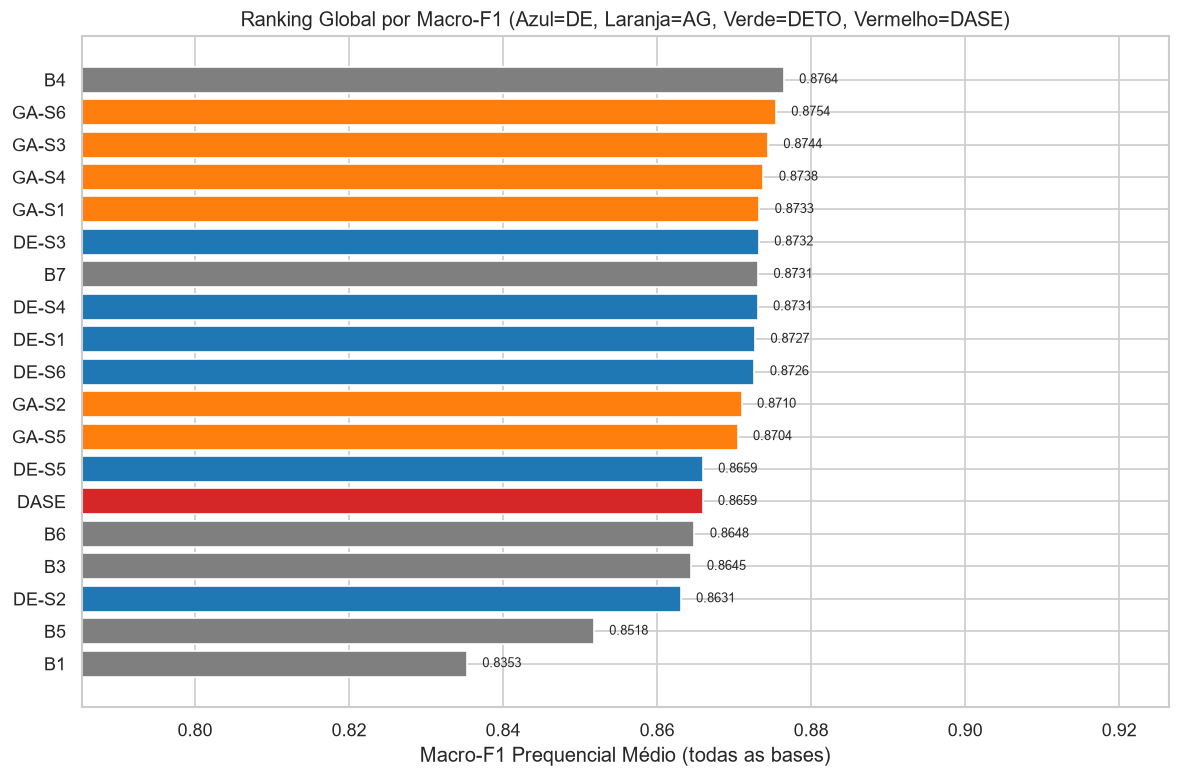

In [16]:
# Identifica a melhor estratégia de DE e de AG pela média geral de macro-F1
de_methods = [c for c in mean_f1.columns if c.startswith("DE-")]
ga_methods = [c for c in mean_f1.columns if c.startswith("GA-")]

best_de = mean_f1[de_methods].mean().idxmax() if de_methods else None
best_ga = mean_f1[ga_methods].mean().idxmax() if ga_methods else None
print(f"Melhor DE: {best_de} | Melhor GA: {best_ga}")

# Gráfico de barras da média global de Macro-F1 por método
global_means = mean_f1.mean().sort_values(ascending=True)
colors = [
    "#1f77b4" if m.startswith("DE-") else
    "#ff7f0e" if m.startswith("GA-") else
    "#2ca02c" if m == "DETO" else
    "#d62728" if m == "DASE" else
    "#7f7f7f"
    for m in global_means.index
]

fig, ax = plt.subplots(figsize=(10, max(4.5, 0.35 * len(global_means))))
ax.barh(global_means.index, global_means.values, color=colors)
for i, v in enumerate(global_means.values):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=8)
ax.set_xlabel("Macro-F1 Prequencial Médio (todas as bases)")
ax.set_title("Ranking Global por Macro-F1 (Azul=DE, Laranja=AG, Verde=DETO, Vermelho=DASE)")
ax.set_xlim(max(0.0, global_means.min() - 0.05), min(1.0, global_means.max() + 0.05))
fig.tight_layout()
fig.savefig(FIG_DIR / "global_macro_f1.png", dpi=150)
plt.show()

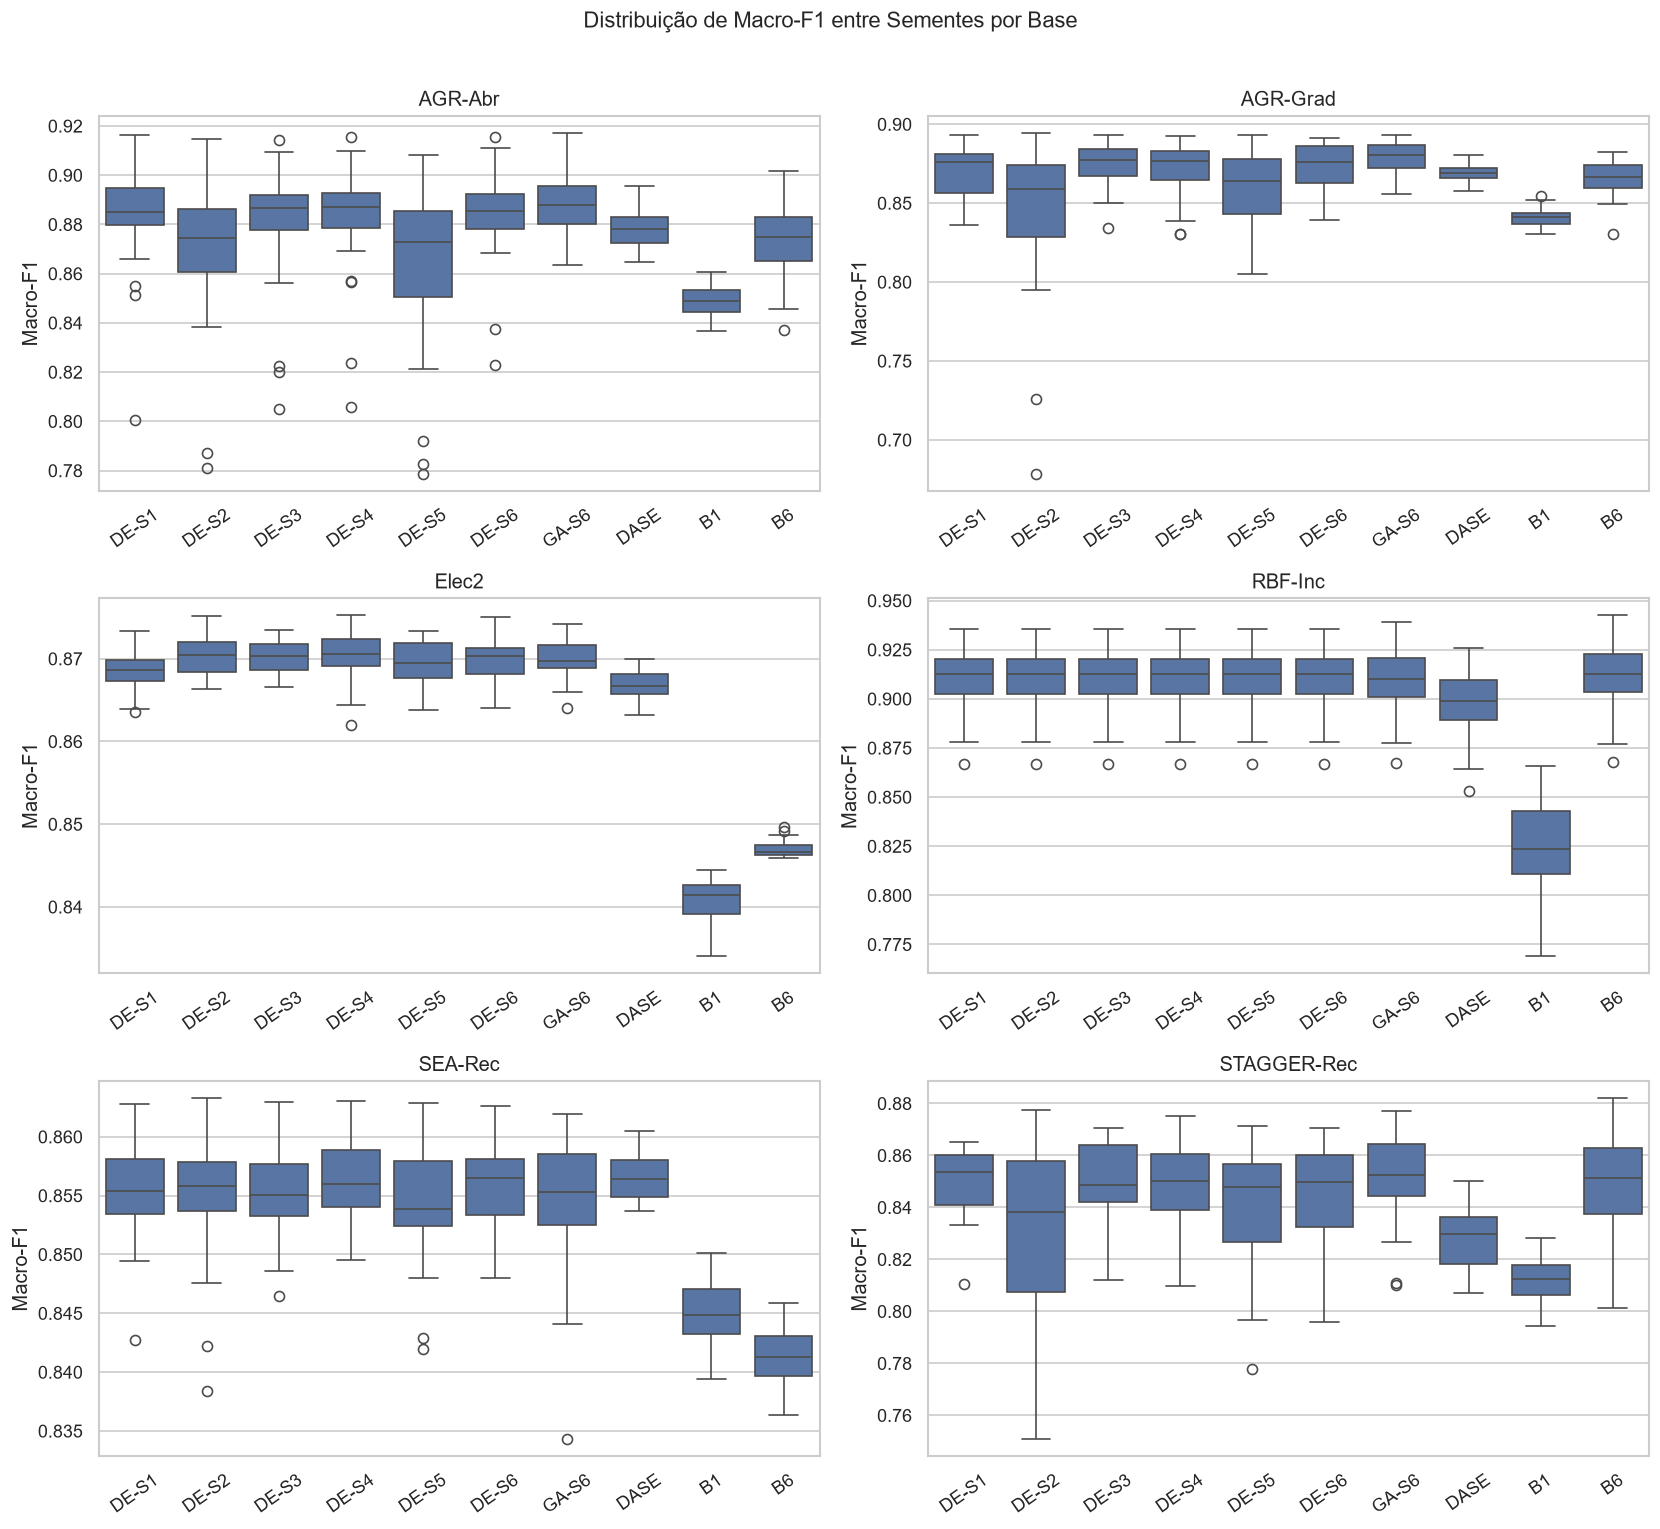

In [17]:
# Boxplots por base: foco nos métodos principais (DE-S1..S6, melhor GA, DETO, DASE)
focus_methods = de_methods + ([best_ga] if best_ga else []) + [m for m in ("DETO", "DASE", "B1", "B6") if m in mean_f1.columns]
sub = core[core["method"].isin(focus_methods)]
datasets = sorted(sub["dataset"].unique())

ncols = 2
nrows = int(np.ceil(len(datasets) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.2 * nrows), squeeze=False)
for ax, ds in zip(axes.flat, datasets):
    df_ds = sub[sub["dataset"] == ds]
    sns.boxplot(data=df_ds, x="method", y="macro_f1", order=focus_methods, ax=ax)
    ax.set_title(ds)
    ax.set_xlabel("")
    ax.set_ylabel("Macro-F1")
    ax.tick_params(axis="x", rotation=35)
for ax in axes.flat[len(datasets):]:
    ax.axis("off")
fig.suptitle("Distribuição de Macro-F1 entre Sementes por Base", y=1.01, fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "boxplots_macro_f1.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Análise Estatística (Friedman + Nemenyi e Wilcoxon + Holm + $\hat{A}_{12}$)

=== DE (S1–S6), Melhor AG, DETO/DASE e Baselines ===
Friedman p-valor = 5.505e-170 | CD (Nemenyi, α=0.05) = 1.479 | N = 180 blocos | k = 14 métodos


,Rank Médio
method,
GA-S6,4.788889
DE-S4,5.530556
DE-S3,5.558333
B4,5.566667
DE-S6,5.730556
DE-S1,5.797222
B7,6.272222
DE-S2,7.180556
DE-S5,7.297222


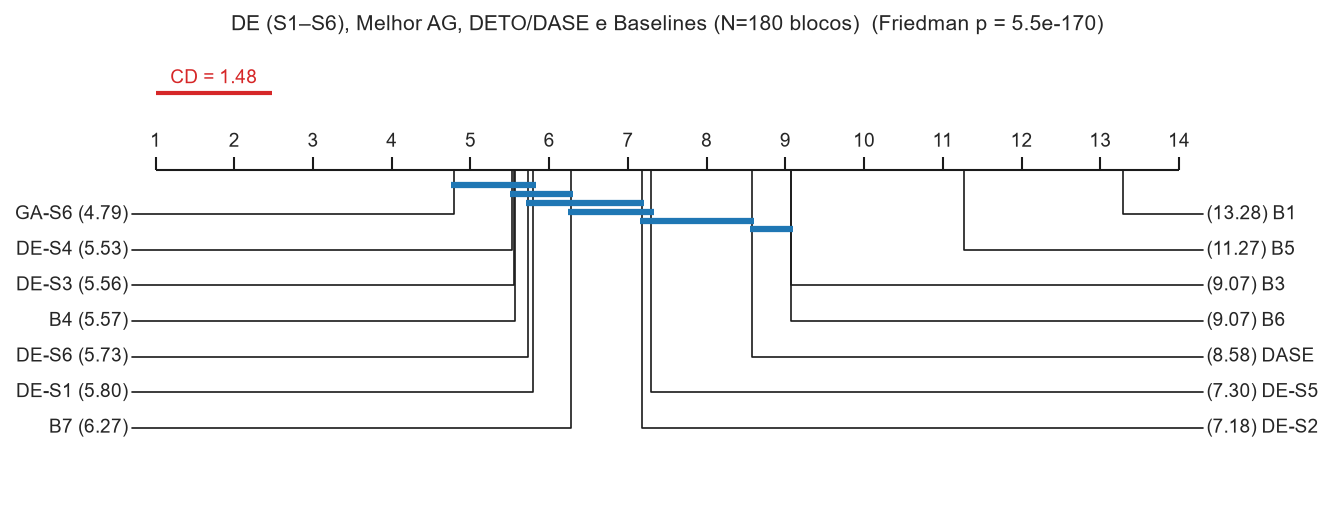

=== Melhor DE vs Melhor AG vs DETO/DASE vs Baselines ===
Friedman p-valor = 8.582e-151 | CD (Nemenyi, α=0.05) = 0.895 | N = 180 blocos | k = 9 métodos


,Rank Médio
method,
GA-S6,2.838889
B4,3.205556
DE-S3,3.344444
B7,3.638889
DASE,5.066667
B6,5.683333
B3,5.700000
B5,6.916667
B1,8.605556


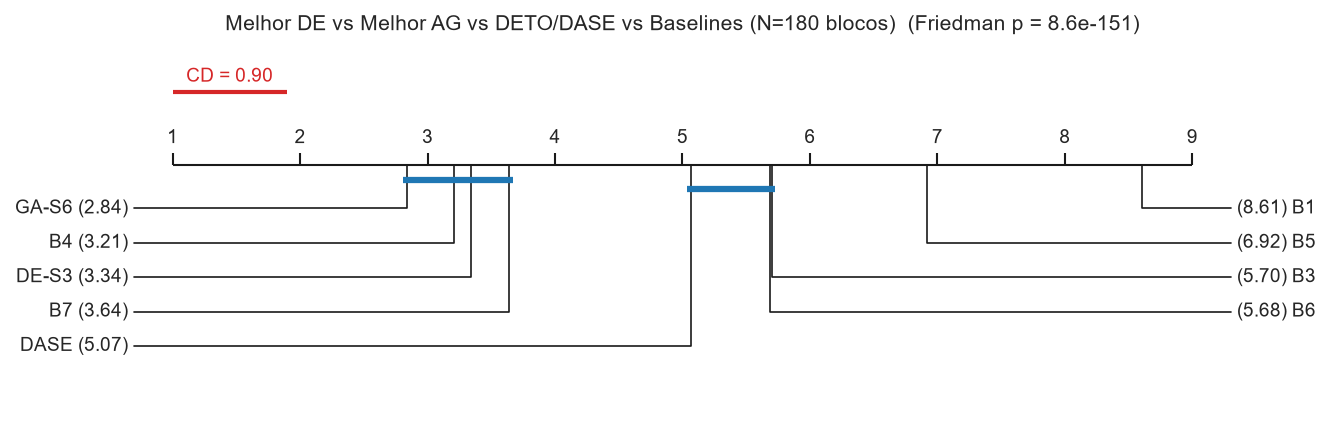

In [18]:
# Friedman + Nemenyi usando blocos = (dataset, seed) para maior poder estatístico
baseline_methods = sorted([c for c in mean_f1.columns if c.startswith("B")])
bench_methods = [c for c in ("ARF", "SRP", "LeveragingBagging") if c in mean_f1.columns]
extra_methods = [m for m in ("DETO", "DASE") if m in mean_f1.columns]

cd_specs = [
    (
        "cd_completo.png",
        "DE (S1–S6), Melhor AG, DETO/DASE e Baselines",
        de_methods + ([best_ga] if best_ga else []) + extra_methods + baseline_methods + bench_methods,
    ),
    (
        "cd_resumo_baselines.png",
        "Melhor DE vs Melhor AG vs DETO/DASE vs Baselines",
        ([best_de] if best_de else []) + ([best_ga] if best_ga else []) + extra_methods + baseline_methods + bench_methods,
    ),
]

for fname, title, methods_list in cd_specs:
    # Remove duplicatas preservando ordem
    methods_list = list(dict.fromkeys(methods_list))
    piv = core[core["method"].isin(methods_list)].pivot_table(
        index=["dataset", "seed"], columns="method", values="macro_f1"
    ).dropna()
    if len(piv) >= 3 and 3 <= len(methods_list) <= 20:
        fr = friedman_nemenyi(piv[methods_list])
        print(f"=== {title} ===")
        print(f"Friedman p-valor = {fr['p_value']:.4g} | CD (Nemenyi, α=0.05) = {fr['cd']:.3f} | N = {fr['N']} blocos | k = {fr['k']} métodos")
        display(fr["avg_ranks"].to_frame("Rank Médio"))
        cd_path = FIG_DIR / fname
        cd_diagram(fr["avg_ranks"], fr["cd"], f"{title} (N={fr['N']} blocos)", str(cd_path), fr["p_value"])
        display(Image(filename=str(cd_path)))
    else:
        print(f"Pulando {title}: N={len(piv)}, k={len(methods_list)} (necessário N>=3 e 3<=k<=20).")

In [19]:
# Wilcoxon pareado (sementes) + correção de Holm + efeito Â12 por base (incluindo todos os baselines)
comps = []
if best_de:
    targets = ([best_ga] if best_ga else []) + extra_methods + baseline_methods + bench_methods
    for target in list(dict.fromkeys(targets)):
        if target and target in mean_f1.columns and target != best_de:
            comps.append((best_de, target))
    if "DE-S1" in de_methods:
        for s in de_methods:
            if s != "DE-S1":
                comps.append((s, "DE-S1"))

w_rows = []
for ds in sorted(core["dataset"].unique()):
    sub_ds = core[core["dataset"] == ds].pivot_table(index="seed", columns="method", values="macro_f1")
    valid_comps = [(a, b) for a, b in comps if a in sub_ds.columns and b in sub_ds.columns]
    if not valid_comps:
        continue
    pvals = [wilcoxon_p(sub_ds[a].dropna(), sub_ds[b].dropna()) for a, b in valid_comps]
    padj = holm(pvals)
    for (a, b), p, pa in zip(valid_comps, pvals, padj):
        xa, xb = sub_ds[a].dropna(), sub_ds[b].dropna()
        e = a12(xa, xb)
        diff = float(xa.mean() - xb.mean())
        res = "=" if pa >= 0.05 else ("+" if diff > 0 else "−")
        w_rows.append({
            "dataset": ds,
            "comparação": f"{a} vs {b}",
            "Δ macro-F1": diff,
            "p (Holm)": pa,
            "Â12": e,
            "efeito": a12_label(e),
            "resultado": res,
        })

wilcoxon_df = pd.DataFrame(w_rows)
if not wilcoxon_df.empty:
    display(wilcoxon_df)
    summary_wl = wilcoxon_df.groupby("comparação")["resultado"].apply(
        lambda r: f"{(r == '+').sum()}/{(r == '=').sum()}/{(r == '−').sum()}"
    ).to_frame("Vitórias / Empates / Derrotas")
    display(summary_wl)

,dataset,comparação,Δ macro-F1,p (Holm),Â12,efeito,resultado
0,AGR-Abr,DE-S3 vs GA-S6,-0.008737,0.078349,0.426667,pequeno,=
1,AGR-Abr,DE-S3 vs DASE,0.001953,0.269443,0.667778,médio,=
2,AGR-Abr,DE-S3 vs B1,0.031148,0.000067,0.895556,grande,+
3,AGR-Abr,DE-S3 vs B3,0.006371,0.148236,0.677778,médio,=
4,AGR-Abr,DE-S3 vs B4,-0.009027,0.885964,0.424444,pequeno,=
...,...,...,...,...,...,...,...
73,STAGGER-Rec,DE-S2 vs DE-S1,-0.018970,0.016776,0.345556,médio,−
74,STAGGER-Rec,DE-S3 vs DE-S1,-0.000063,1.000000,0.511111,desprezível,=
75,STAGGER-Rec,DE-S4 vs DE-S1,-0.000915,1.000000,0.491111,desprezível,=
76,STAGGER-Rec,DE-S5 vs DE-S1,-0.009513,0.079452,0.405556,pequeno,=


,Vitórias / Empates / Derrotas
comparação,
DE-S2 vs DE-S1,1/3/2
DE-S3 vs B1,6/0/0
DE-S3 vs B3,2/4/0
DE-S3 vs B4,2/2/2
DE-S3 vs B5,6/0/0
DE-S3 vs B6,2/4/0
DE-S3 vs B7,1/5/0
DE-S3 vs DASE,3/3/0
DE-S3 vs DE-S1,1/5/0


## 4. Curvas Temporais de Macro-F1 em Janela Deslizante

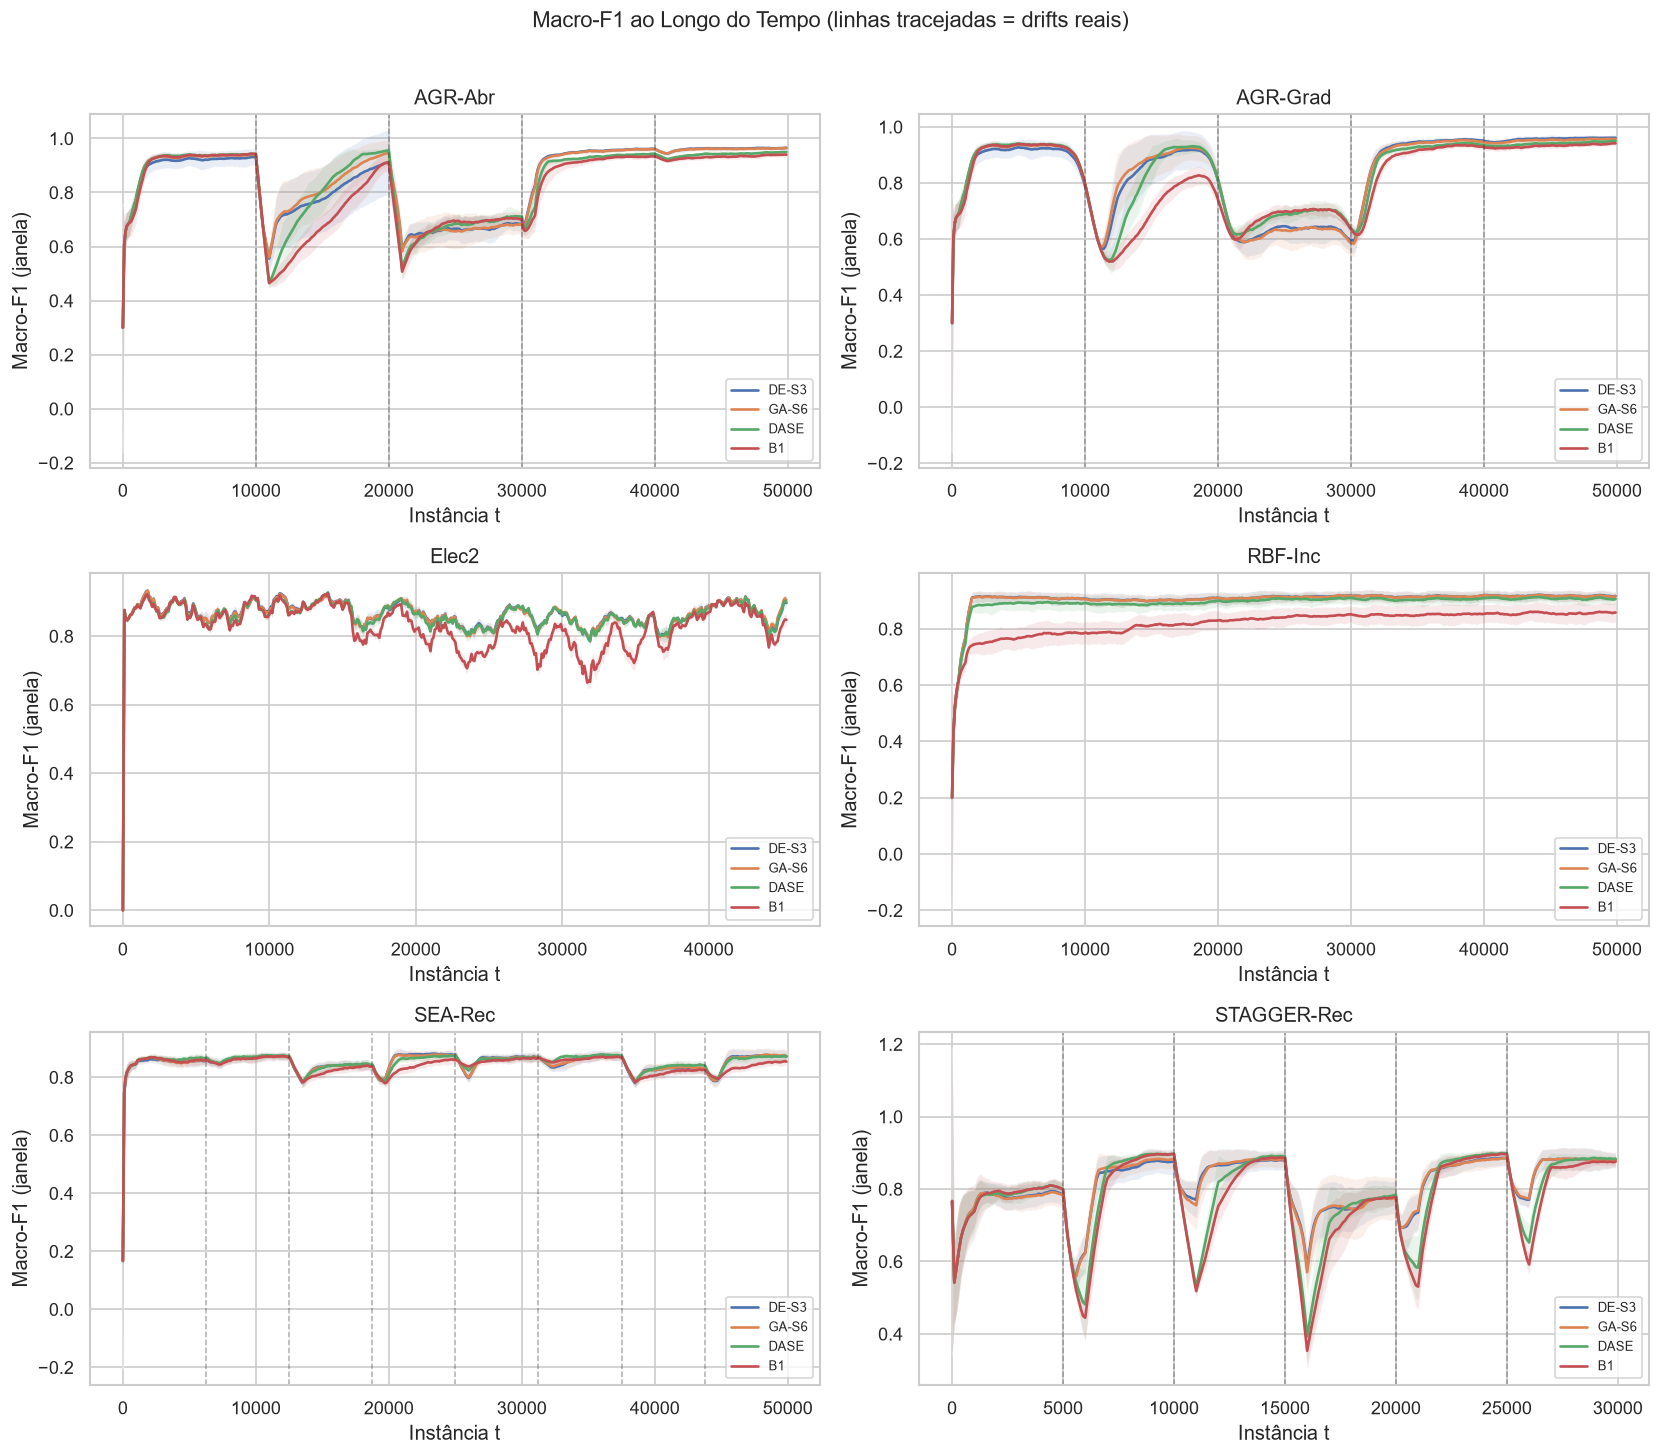

In [20]:
curve_methods = [m for m in [best_de, best_ga, "DETO", "DASE", "B1"] if m and m in mean_f1.columns]
datasets = sorted(runs["dataset"].unique())

if len(curves) > 0 and curve_methods:
    ncols = 2
    nrows = int(np.ceil(len(datasets) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.0 * nrows), squeeze=False)
    for ax, ds in zip(axes.flat, datasets):
        for m in curve_methods:
            arrs = [curves[k] for k in curves.files if k.startswith(f"{ds}|{m}|")]
            if not arrs:
                continue
            min_len = min(len(a) for a in arrs)
            mat = np.vstack([a[:min_len] for a in arrs])
            x = np.arange(min_len) * CURVE_STEP
            mu = mat.mean(axis=0)
            sd = mat.std(axis=0)
            ax.plot(x, mu, label=m, lw=1.6)
            ax.fill_between(x, mu - sd, mu + sd, alpha=0.12)
        for dpos in DRIFTS.get(ds, []):
            if dpos <= x[-1]:
                ax.axvline(dpos, color="k", ls="--", alpha=0.35, lw=0.9)
        ax.set_title(ds)
        ax.set_xlabel("Instância t")
        ax.set_ylabel("Macro-F1 (janela)")
        ax.legend(fontsize=8, loc="lower right")
    for ax in axes.flat[len(datasets):]:
        ax.axis("off")
    fig.suptitle("Macro-F1 ao Longo do Tempo (linhas tracejadas = drifts reais)", y=1.01, fontsize=13)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "curves_over_time.png", dpi=150, bbox_inches="tight")
    plt.show()

## 5. Reação Pós-Drift, Convergência e Custo Computacional

,macro_f1,max_drop,recovery_time,n_events,n_evals,gens_to_95,replay_time_s,time_per_inst_ms
method,,,,,,,,
B4,0.8764,0.1238,2455.1563,NaN,NaN,NaN,0.0667,1.4244
GA-S6,0.8754,0.1480,2667.3535,4.5222,4133.4222,14.5430,0.3556,1.4311
GA-S3,0.8744,0.1486,2694.9521,4.4667,4291.3556,15.8545,0.3572,1.4311
GA-S4,0.8738,0.1457,2681.0150,4.4222,3932.4000,11.7715,0.3308,1.4305
GA-S1,0.8733,0.1492,2685.8842,4.5889,4293.7778,14.7126,0.3575,1.4312
DE-S3,0.8732,0.1439,2637.3223,4.6222,4957.5000,16.0216,0.4560,1.4334
B7,0.8731,0.1538,2723.6540,4.7556,8633.3333,21.8471,0.5859,1.4364
DE-S4,0.8731,0.1419,2628.5253,4.5111,4780.0000,14.4404,0.4431,1.4330
DE-S1,0.8727,0.1448,2646.1876,4.6278,5252.3333,17.8238,0.4796,1.4340


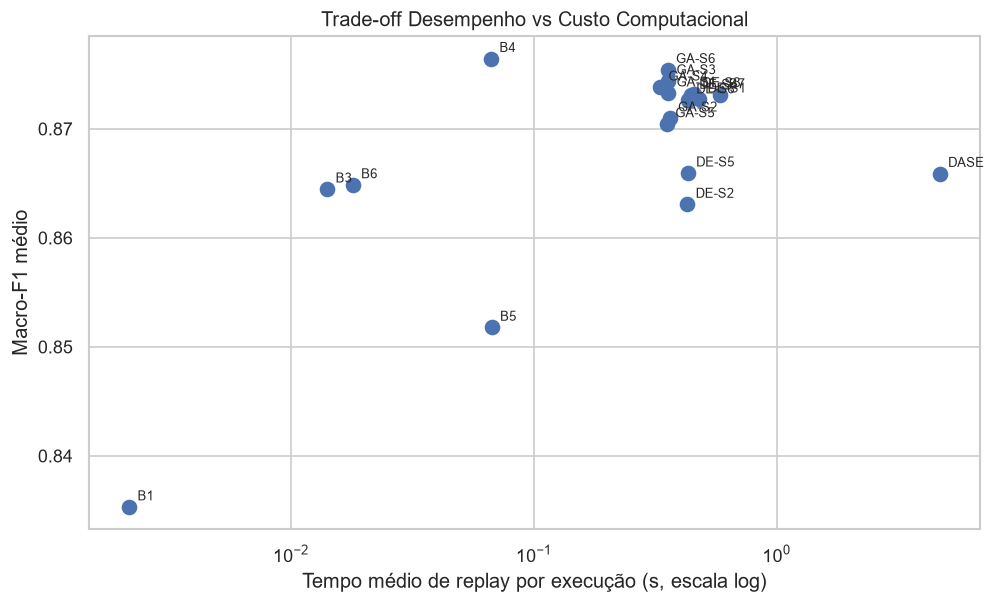

In [21]:
cost_cols = [c for c in [
    "macro_f1", "max_drop", "recovery_time", "n_events", "n_evals",
    "gens_to_95", "replay_time_s", "time_per_inst_ms"
] if c in runs.columns]

cost_summary = core.groupby("method")[cost_cols].mean().sort_values("macro_f1", ascending=False)
display(cost_summary.round(4))

# Scatter trade-off: Macro-F1 vs tempo de replay (s)
if "replay_time_s" in cost_summary.columns:
    plot_df = cost_summary.dropna(subset=["replay_time_s"])
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    ax.scatter(plot_df["replay_time_s"], plot_df["macro_f1"], s=70)
    for name, row in plot_df.iterrows():
        ax.annotate(name, (row["replay_time_s"], row["macro_f1"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("Tempo médio de replay por execução (s, escala log)")
    ax.set_ylabel("Macro-F1 médio")
    ax.set_title("Trade-off Desempenho vs Custo Computacional")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "tradeoff_f1_time.png", dpi=150)
    plt.show()

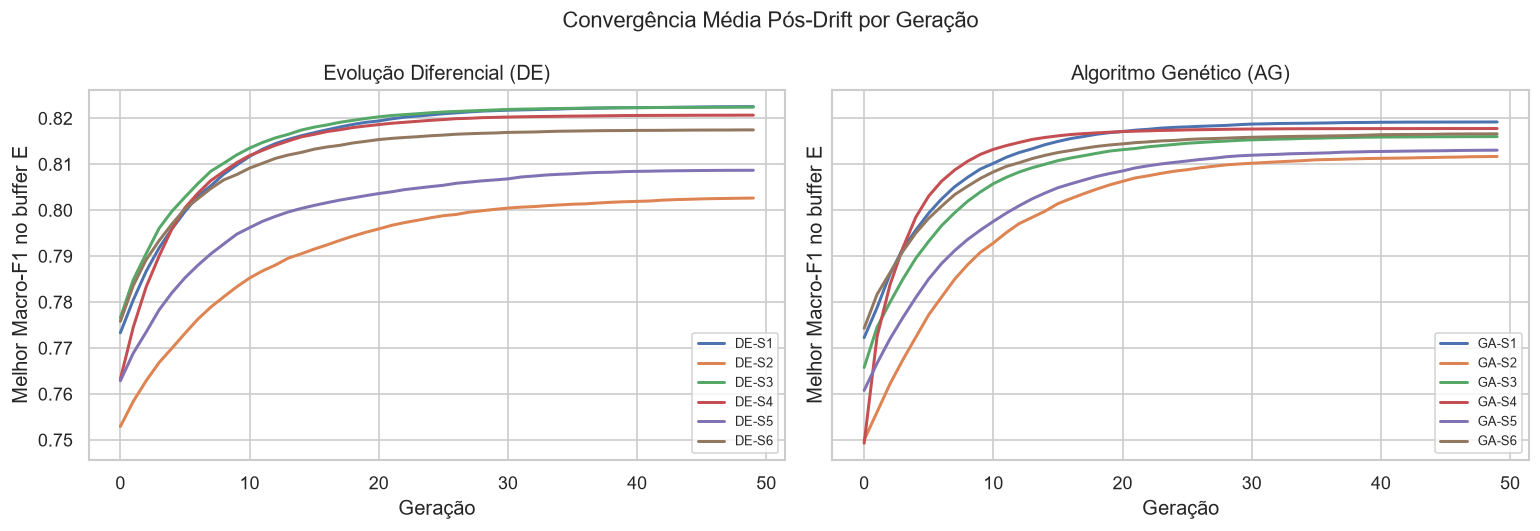

In [22]:
# Curva de convergência por geração (DE-S1..S6 vs GA-S1..S6) extraída de events.csv
if not events.empty and "history" in events.columns:
    post = events[(events["initial"] == False) & (events["method"].str.startswith(("DE-", "GA-")))].copy()
    if not post.empty:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
        for ax, prefix, title in zip(axes, ["DE-", "GA-"], ["Evolução Diferencial (DE)", "Algoritmo Genético (AG)"]):
            sub_ev = post[post["method"].str.startswith(prefix)]
            for m in sorted(sub_ev["method"].unique()):
                hists = [json.loads(h) for h in sub_ev[sub_ev["method"] == m]["history"] if h and h != "[]"]
                if not hists:
                    continue
                max_g = max(len(h) for h in hists)
                padded = np.array([h + [h[-1]] * (max_g - len(h)) for h in hists])
                ax.plot(padded.mean(axis=0), label=m, lw=1.8)
            ax.set_title(title)
            ax.set_xlabel("Geração")
            ax.set_ylabel("Melhor Macro-F1 no buffer E")
            ax.legend(fontsize=8)
        fig.suptitle("Convergência Média Pós-Drift por Geração", fontsize=13)
        fig.tight_layout()
        fig.savefig(FIG_DIR / "convergence_de_vs_ga.png", dpi=150)
        plt.show()

## 6. Análise de Detectores (ADWIN vs DDM vs Oráculo — Hipótese H5)

=== Macro-F1 médio de DE (S1–S6) por Detector ===


detector,adwin,ddm,oracle
dataset,,,
AGR-Abr,0.8769,0.8720,0.8753
AGR-Grad,0.8650,0.8647,0.8643
RBF-Inc,0.9095,0.9096,NaN
SEA-Rec,0.8555,0.8471,0.8559
STAGGER-Rec,0.8439,0.8429,0.8380
Média Geral,0.8701,0.8673,0.8584



=== Métricas dos Detectores (média nas bases sintéticas) ===


,detection_delay,false_alarms,missed_drifts,n_events
detector,,,,
adwin,106.925,0.303,1.139,3.351
ddm,214.754,2.574,2.436,4.389
oracle,0.000,0.000,0.000,5.000


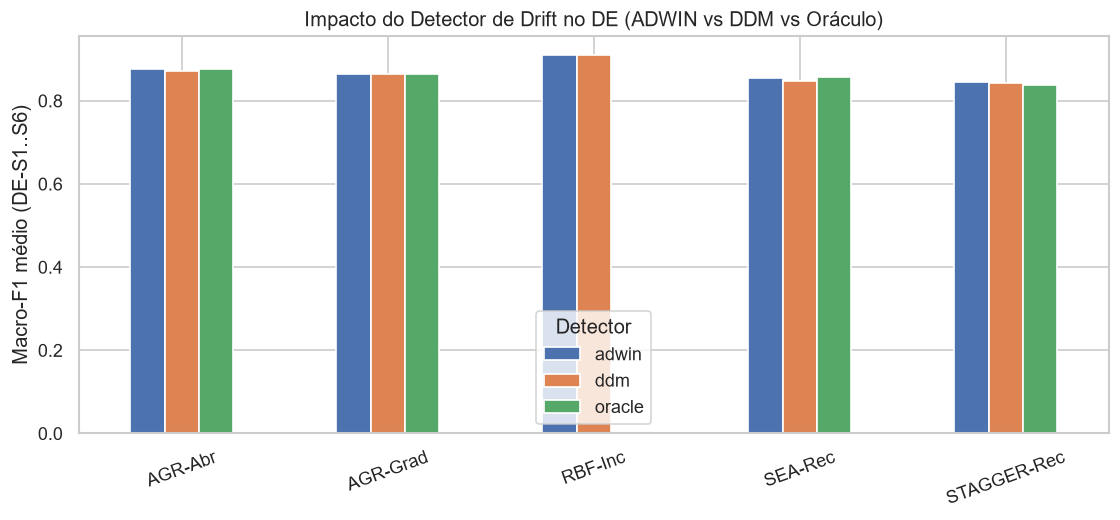

In [23]:
det_df = runs[runs["block"].isin(["de", "detector"])].copy()
if "detector" in runs["block"].values:
    # Filtra apenas bases que possuem mais de um detector avaliado
    multi_det_ds = det_df.groupby("dataset")["detector"].nunique()
    multi_det_ds = sorted(multi_det_ds[multi_det_ds > 1].index)
    det_sub = det_df[det_df["dataset"].isin(multi_det_ds)]

    det_f1 = det_sub.groupby(["dataset", "detector"])["macro_f1"].mean().unstack()
    det_f1.loc["Média Geral"] = det_f1.mean()
    print("=== Macro-F1 médio de DE (S1–S6) por Detector ===")
    display(det_f1.round(4))

    det_cols = [c for c in ["detection_delay", "false_alarms", "missed_drifts", "n_events"] if c in det_sub.columns]
    if det_cols:
        print("\n=== Métricas dos Detectores (média nas bases sintéticas) ===")
        display(det_sub.groupby("detector")[det_cols].mean().round(3))

    fig, ax = plt.subplots(figsize=(9.5, 4.5))
    det_f1.drop(index="Média Geral").plot(kind="bar", ax=ax)
    ax.set_ylabel("Macro-F1 médio (DE-S1..S6)")
    ax.set_xlabel("")
    ax.set_title("Impacto do Detector de Drift no DE (ADWIN vs DDM vs Oráculo)")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Detector")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "detector_comparison.png", dpi=150)
    plt.show()
else:
    print("Bloco 'detector' não presente neste runs.csv. Rode com --blocks ... detector para ativar.")

## 7. Análise de Sensibilidade da Evolução Diferencial

Referência padrão DE (AGR-Abr, SEA-Rec): macro-F1 = 0.8662


macro_f1    n_evals  replay_time_s  \
factor         value                                                       
G              100                      0.8657  4455.6667         0.3944   
               20                       0.8682  2836.1667         0.2750   
N              10                       0.8626  1478.6944         0.1963   
               50                       0.8645  6897.2222         0.5525   
de_CR          0.5                      0.8662  4418.5833         0.3897   
               0.7                      0.8627  3931.0000         0.3570   
de_F           0.3                      0.8662  4418.5833         0.3946   
               0.8                      0.8662  4418.5833         0.3930   
de_strategy    best/1/bin               0.8592  3321.7500         0.3082   
               current-to-best/1/bin    0.8621  3805.5000         0.3476   
               rand/1/bin               0.8626  4468.6667         0.3871   
immigrant_rate 0.1                      0.8654  4422.0000         0.3919   
               0.5                      0.8658  4363.3333         0.3918   
n_min          100                      0.8498  3290.0833         0.2340   
               200                      0.8540  3629.6667         0.2639   

                                      Δ vs padrão  
factor         value                               
G              100                        -0.0005  
               20                          0.0020  
N              10                         -0.0036  
               50                         -0.0017  
de_CR          0.5                         0.0000  
               0.7                        -0.0035  
de_F           0.3                         0.0000  
               0.8                         0.0000  
de_strategy    best/1/bin                 -0.0070  
               current-to-best/1/bin      -0.0041  
               rand/1/bin                 -0.0036  
immigrant_rate 0.1                        -0.0007  
               0.5                        -0.0003  
n_min          100                        -0.0163  
               200                        -0.0122

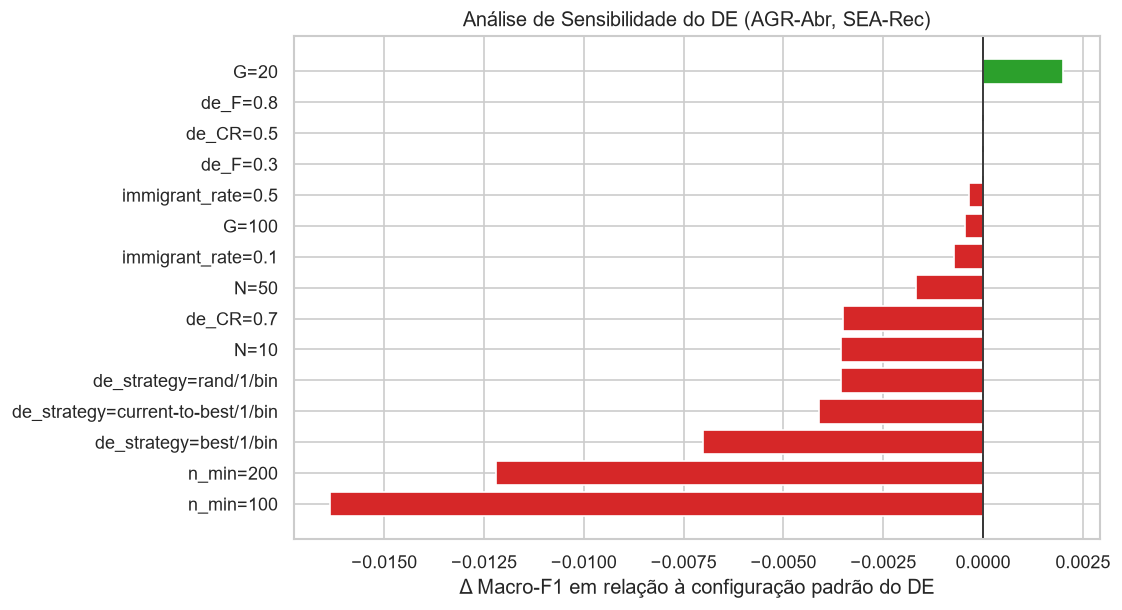

In [24]:
sens_df = runs[runs["block"] == "sensitivity"].copy()
if not sens_df.empty and "factor" in sens_df.columns:
    sens_ds = sorted(sens_df["dataset"].unique())
    base_de_mean = core[(core["block"] == "de") & (core["dataset"].isin(sens_ds))]["macro_f1"].mean()

    sens_tab = sens_df.groupby(["factor", "value"])[["macro_f1", "n_evals", "replay_time_s"]].mean()
    sens_tab["Δ vs padrão"] = sens_tab["macro_f1"] - base_de_mean
    print(f"Referência padrão DE ({', '.join(sens_ds)}): macro-F1 = {base_de_mean:.4f}")
    display(sens_tab.round(4))

    sens_plot = sens_tab.reset_index()
    sens_plot["label"] = sens_plot["factor"].astype(str) + "=" + sens_plot["value"].astype(str)
    sens_plot = sens_plot.sort_values("Δ vs padrão")

    fig, ax = plt.subplots(figsize=(9.5, max(4.5, 0.35 * len(sens_plot))))
    colors = ["#2ca02c" if v >= 0 else "#d62728" for v in sens_plot["Δ vs padrão"]]
    ax.barh(sens_plot["label"], sens_plot["Δ vs padrão"], color=colors)
    ax.axvline(0.0, color="k", lw=1.0)
    ax.set_xlabel("Δ Macro-F1 em relação à configuração padrão do DE")
    ax.set_title(f"Análise de Sensibilidade do DE ({', '.join(sens_ds)})")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "sensitivity_de.png", dpi=150)
    plt.show()
else:
    print("Bloco 'sensitivity' não presente neste runs.csv. Rode com --blocks ... sensitivity para ativar.")